# UAV Visual Localization | DINOv2, SIFT, LightGlue

- **Task** (take-home assignment): find where each of 344 drone photos (UAV-VisLoc, subset 06) was taken on one satellite map. GPS labels are used only for the final evaluation. Metric: Mean Haversine Error (MHE, metres).
- **Approach** (no training): DINOv2 finds the most similar map tiles, keypoint matching + homography refines the position inside them.
- **Reference from the task:** MHE 816 m. **Experiments:** SuperPoint + LightGlue instead of SIFT; smoothing over 5 frames.
- **Data:** Kaggle dataset `hailong1610/uav-visloc-dataset` (Apache-2.0). **Runtime:** ~1.5 h on a T4 GPU. **Results:** section 7.

## 1: Setup

In [1]:
!pip install -q rasterio git+https://github.com/cvg/LightGlue.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, random, urllib.request
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
cv2.setRNGSeed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

assert torch.cuda.is_available(), "Turn on a GPU: Settings -> Accelerator -> GPU T4"
_ = urllib.request.urlopen("https://pypi.org", timeout=10)  # fail fast if Internet is off
DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


In [3]:
def find_subset_dir(name="06"):
    """Find the folder with satellite<name>.tif under /kaggle/input (image folders are skipped)."""
    for root, dirs, files in os.walk("/kaggle/input"):
        if f"satellite{name}.tif" in files:
            return Path(root)
        dirs[:] = [d for d in dirs if d.lower() != "drone"]
    raise FileNotFoundError("Attach the Kaggle dataset 'hailong1610/uav-visloc-dataset' as Input.")

SUBSET_DIR = find_subset_dir("06")
DRONE_DIR = SUBSET_DIR / "drone"
SATELLITE_PATH = SUBSET_DIR / "satellite06.tif"
GT_PATH = SUBSET_DIR / "06.csv"  # existence check only: first read in section 7
OUTPUT_DIR = Path("/kaggle/working/outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

drone_paths = sorted(DRONE_DIR.glob("*.JPG"))
print("Subset folder:", SUBSET_DIR)
print("UAV images:", len(drone_paths), "| GT file exists:", GT_PATH.exists())

Subset folder: /kaggle/input/datasets/hailong1610/uav-visloc-dataset/06
UAV images: 344 | GT file exists: True


## 2: Map bounds and data examples

The map bounds come from `satellite_coordinates_range.csv` (part of the dataset). If that file is missing, the same bounds are read from the GeoTIFF header. They are allowed input: they only convert map pixels to latitude / longitude.

In [4]:
range_files = [p for p in SUBSET_DIR.parent.glob("*.csv") if "coordinates_range" in p.name]
if range_files:
    ranges = pd.read_csv(range_files[0])
    row = ranges.loc[ranges["mapname"].str.strip().eq(SATELLITE_PATH.name)].iloc[0]
    LT_LAT, LT_LON, RB_LAT, RB_LON = (float(row[c]) for c in ["LT_lat_map", "LT_lon_map", "RB_lat_map", "RB_lon_map"])
    bounds_source = range_files[0].name
else:
    import rasterio
    with rasterio.open(SATELLITE_PATH) as src:
        b = src.bounds
    LT_LAT, LT_LON, RB_LAT, RB_LON = b.top, b.left, b.bottom, b.right
    bounds_source = "GeoTIFF header"

Image.MAX_IMAGE_PIXELS = None
with Image.open(SATELLITE_PATH) as im:
    satellite_rgb = np.asarray(im.convert("RGB")).copy()
MAP_H, MAP_W = satellite_rgb.shape[:2]

print(f"Satellite map: {MAP_W} x {MAP_H} px")
print(f"Bounds ({bounds_source}): top-left {LT_LAT:.6f}, {LT_LON:.6f} | bottom-right {RB_LAT:.6f}, {RB_LON:.6f}")

Satellite map: 8082 x 9780 px
Bounds (satellite_ coordinates_range.csv): top-left 32.373177, 109.635160 | bottom-right 32.346944, 109.656837


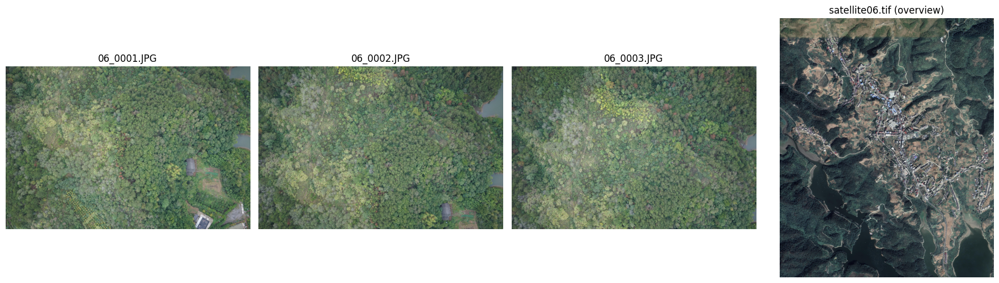

In [5]:
def read_rgb(path):
    with Image.open(path) as image:
        return np.asarray(image.convert("RGB")).copy()

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, path in zip(axes[:3], drone_paths[:3]):
    ax.imshow(read_rgb(path)); ax.set_title(path.name); ax.axis("off")
axes[3].imshow(satellite_rgb[::8, ::8]); axes[3].set_title("satellite06.tif (overview)"); axes[3].axis("off")
plt.tight_layout(); plt.show()

## 3: Satellite tile database

The map is cut into tiles at three scales with the 3:2 shape of the drone photos, with a stride of 336 px (tiles overlap). Each tile is stored as-is and rotated by 180°, because the drone's heading is unknown (the heading in `06.csv` is not used).

In [6]:
TILE_SCALES = {"small": (1536, 1024), "medium": (1792, 1194), "large": (2048, 1366)}
TILE_STRIDE = 336
COARSE_ROTATIONS = (0, 180)

def sliding_starts(full_length, tile_length, stride):
    starts = list(range(0, full_length - tile_length + 1, stride))
    if starts[-1] != full_length - tile_length:
        starts.append(full_length - tile_length)
    return starts

tile_records = [
    {"scale": s, "x": x, "y": y, "w": w, "h": h, "cx": x + w / 2, "cy": y + h / 2, "rotation": r}
    for s, (w, h) in TILE_SCALES.items()
    for y in sliding_starts(MAP_H, h, TILE_STRIDE)
    for x in sliding_starts(MAP_W, w, TILE_STRIDE)
    for r in COARSE_ROTATIONS
]

def tile_rgb(record):
    crop = satellite_rgb[record["y"]:record["y"] + record["h"], record["x"]:record["x"] + record["w"]]
    return cv2.rotate(crop, cv2.ROTATE_180) if record["rotation"] == 180 else crop

print(f"Tiles (with rotations): {len(tile_records):,}")
print(pd.DataFrame(tile_records).groupby(["scale", "rotation"]).size().rename("tiles").to_string())

Tiles (with rotations): 3,282
scale   rotation
large   0           513
        180         513
medium  0           540
        180         540
small   0           588
        180         588


## 4: DINOv2 embeddings and coarse retrieval

DINOv2 ViT-B/14 (pretrained, self-supervised, not trained here) turns each image into a 768-number vector. Vectors are L2-normalised, so cosine similarity is a dot product. For each drone photo, the 8 most similar tiles whose centres are at least 336 px apart become the candidates.

In [7]:
DINO_INPUT_HW = (224, 336)  # both sides divisible by the DINOv2 patch size 14
DINO_BATCH_SIZE = 24
dino = torch.hub.load("facebookresearch/dinov2", "dinov2_vitb14", pretrained=True, trust_repo=True).to(DEVICE).eval()
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

@torch.inference_mode()
def embed_batch(images):
    batch = torch.stack([
        (torch.from_numpy(cv2.resize(im, DINO_INPUT_HW[::-1], interpolation=cv2.INTER_AREA)).permute(2, 0, 1).float() / 255 - MEAN) / STD
        for im in images]).to(DEVICE)
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        emb = dino(batch)
    return torch.nn.functional.normalize(emb.float(), dim=1).cpu()

def embed_all(items, load, desc):
    chunks = [embed_batch([load(i) for i in items[s:s + DINO_BATCH_SIZE]])
              for s in tqdm(range(0, len(items), DINO_BATCH_SIZE), desc=desc, mininterval=30)]
    return torch.cat(chunks).numpy()

reference_embeddings = embed_all(tile_records, tile_rgb, "satellite tiles")
query_embeddings = embed_all(drone_paths, read_rgb, "UAV images")
print(reference_embeddings.shape, query_embeddings.shape)

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitb14_pretrain.pth


100%|██████████| 330M/330M [00:00<00:00, 474MB/s]
UAV images: 100%|██████████| 15/15 [01:15<00:00,  5.00s/it]

(3282, 768) (344, 768)


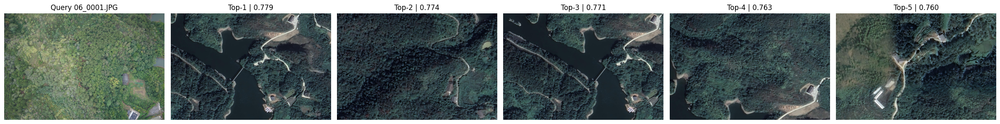

In [8]:
RETRIEVAL_POOL = 80
LOCAL_TOPK = 8
MIN_CENTER_SEPARATION = 336

def distinct_candidates(similarities):
    ranked = np.argsort(-similarities)[:RETRIEVAL_POOL]
    chosen = []
    for idx in ranked:
        r = tile_records[idx]
        if all(np.hypot(r["cx"] - tile_records[j]["cx"], r["cy"] - tile_records[j]["cy"]) >= MIN_CENTER_SEPARATION for j in chosen):
            chosen.append(int(idx))
        if len(chosen) == LOCAL_TOPK:
            break
    return chosen

coarse_candidate_cache = {p.name: distinct_candidates(reference_embeddings @ q)
                          for p, q in zip(drone_paths, query_embeddings)}

query_index = 0
fig, axes = plt.subplots(1, 6, figsize=(24, 4))
axes[0].imshow(read_rgb(drone_paths[query_index])); axes[0].set_title(f"Query {drone_paths[query_index].name}")
sims = reference_embeddings @ query_embeddings[query_index]
for rank, (ax, t) in enumerate(zip(axes[1:], coarse_candidate_cache[drone_paths[query_index].name]), 1):
    ax.imshow(tile_rgb(tile_records[t])); ax.set_title(f"Top-{rank} | {sims[t]:.3f}")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 5: Local refinement with keypoint matching

DINOv2 says *where to look*, not the exact pixel. The drone photo is matched with a 2500×1700 px map region around each of the 8 candidates; a homography (MAGSAC) projects the photo centre onto the map. Accepted only with ≥ 12 matches, ≥ 12 inliers and an inlier share ≥ 0.15; otherwise the centre of the best tile is used. The matcher is a plug-in: SIFT here, LightGlue in experiment 1, same thresholds.

In [9]:
LOCAL_ROI_W, LOCAL_ROI_H = 2500, 1700
MAX_QUERY_SIDE = 1600
MIN_MATCHES, MIN_INLIERS, MIN_INLIER_RATIO = 12, 12, 0.15
RANSAC_THRESHOLD_PX = 4.0

def resize_longest_side(rgb, max_side=MAX_QUERY_SIDE):
    h, w = rgb.shape[:2]
    s = min(1.0, max_side / max(h, w))
    return rgb if s == 1.0 else cv2.resize(rgb, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)

def crop_roi_at_center(cx, cy):
    x0 = int(np.clip(round(cx - LOCAL_ROI_W / 2), 0, max(0, MAP_W - LOCAL_ROI_W)))
    y0 = int(np.clip(round(cy - LOCAL_ROI_H / 2), 0, max(0, MAP_H - LOCAL_ROI_H)))
    return satellite_rgb[y0:y0 + LOCAL_ROI_H, x0:x0 + LOCAL_ROI_W], x0, y0

def robust_homography(src, dst):
    method = getattr(cv2, "USAC_MAGSAC", cv2.RANSAC)
    return cv2.findHomography(src.reshape(-1, 1, 2), dst.reshape(-1, 1, 2), method, RANSAC_THRESHOLD_PX,
                              maxIters=10_000, confidence=0.999)

In [10]:
def verify_candidate(query, record, backend):
    roi_rgb, x0, y0 = crop_roi_at_center(record["cx"], record["cy"])
    q = query[record["rotation"]] if backend["rotation_aware"] else query[0]
    src, dst = backend["match"](q["feats"], backend["extract"](roi_rgb))
    if len(src) < MIN_MATCHES:
        return None
    H, mask = robust_homography(src, dst)
    if H is None or mask is None:
        return None
    mask = mask.ravel().astype(bool)
    inliers, ratio = int(mask.sum()), float(mask.mean())
    if inliers < MIN_INLIERS or ratio < MIN_INLIER_RATIO:
        return None
    h, w = q["shape"][:2]
    centre = cv2.perspectiveTransform(np.float32([[[w / 2, h / 2]]]), H)[0, 0]
    if not (0 <= centre[0] < roi_rgb.shape[1] and 0 <= centre[1] < roi_rgb.shape[0]):
        return None
    return {"pred_x": float(x0 + centre[0]), "pred_y": float(y0 + centre[1]),
            "matches": len(src), "inliers": inliers, "inlier_ratio": ratio}

In [11]:
def prepare_query(path, backend):
    rgb = resize_longest_side(read_rgb(path))
    # a 180-degree turn keeps the image centre in place, so the projected centre stays valid
    versions = {0: rgb, 180: cv2.rotate(rgb, cv2.ROTATE_180)} if backend["rotation_aware"] else {0: rgb}
    return {r: {"feats": backend["extract"](im), "shape": im.shape} for r, im in versions.items()}

def localize_one(path, query_index, backend):
    query = prepare_query(path, backend)
    candidates = coarse_candidate_cache[path.name]
    verified = []
    for rank, t in enumerate(candidates, 1):
        result = verify_candidate(query, tile_records[t], backend)
        if result:
            result.update(tile_idx=t, coarse_rank=rank)
            verified.append(result)
    top = tile_records[candidates[0]]
    if verified:
        best = max(verified, key=lambda v: (v["inliers"], v["inlier_ratio"]))
        best["source"] = "refined"
    else:
        best = {"pred_x": top["cx"], "pred_y": top["cy"], "matches": 0, "inliers": 0, "inlier_ratio": 0.0,
                "tile_idx": candidates[0], "coarse_rank": 1, "source": "tile centre"}
    best["top1_similarity"] = float(reference_embeddings[candidates[0]] @ query_embeddings[query_index])
    best["filename"] = path.name
    return best

def run_pipeline(backend, name):
    rows = [localize_one(p, i, backend) for i, p in enumerate(tqdm(drone_paths, desc=name, mininterval=30))]
    df = pd.DataFrame(rows)
    df.to_csv(OUTPUT_DIR / f"pred_px_{name}.csv", index=False)
    refined = df[df.source == "refined"]
    print(f"{name}: refined {len(refined)} of {len(df)} images"
          + (f", median inliers {refined.inliers.median():.0f}" if len(refined) else ""))
    return df

In [12]:
sift = cv2.SIFT_create(nfeatures=2500, contrastThreshold=0.02, edgeThreshold=10)
bf_matcher = cv2.BFMatcher(cv2.NORM_L2)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
LOWE_RATIO = 0.78

def sift_extract(rgb):
    kp, desc = sift.detectAndCompute(clahe.apply(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)), None)
    return {"pts": np.float32([k.pt for k in kp]).reshape(-1, 2), "desc": desc}

def ratio_pairs(a, b):
    return {(m.queryIdx, m.trainIdx) for pair in bf_matcher.knnMatch(a, b, k=2) if len(pair) == 2
            for m, n in [pair] if m.distance < LOWE_RATIO * n.distance}

def sift_match(fq, fr):
    a, b = fq["desc"], fr["desc"]
    if a is None or b is None or len(a) < 2 or len(b) < 2:
        return np.zeros((0, 2), np.float32), np.zeros((0, 2), np.float32)
    pairs = sorted(ratio_pairs(a, b) & {(q, r) for r, q in ratio_pairs(b, a)})  # mutual matches only
    return fq["pts"][[q for q, _ in pairs]], fr["pts"][[r for _, r in pairs]]

SIFT_BACKEND = {"extract": sift_extract, "match": sift_match, "rotation_aware": False}  # SIFT is rotation invariant
pred_sift = run_pipeline(SIFT_BACKEND, "dino_sift")

dino_sift: 100%|██████████| 344/344 [1:02:58<00:00, 10.98s/it]

dino_sift: refined 0 of 344 images


## 6: Experiment 1: SuperPoint + LightGlue instead of SIFT

The only change is the matcher: neural keypoints (SuperPoint) matched by LightGlue. SuperPoint is not rotation invariant, so the photo is matched in the same orientation (0° or 180°) as its retrieved tile.

In [13]:
from lightglue import LightGlue, SuperPoint
from lightglue.utils import rbd

superpoint = SuperPoint(max_num_keypoints=2048).eval().to(DEVICE)
lightglue = LightGlue(features="superpoint").eval().to(DEVICE)

@torch.inference_mode()
def lg_extract(rgb):
    image = torch.from_numpy(rgb).permute(2, 0, 1).float().div(255).to(DEVICE)
    return superpoint.extract(image)  # resizes internally; keypoints come back in input pixels

@torch.inference_mode()
def lg_match(feats_q, feats_r):
    matches = rbd(lightglue({"image0": feats_q, "image1": feats_r}))["matches"]
    kq, kr = rbd(feats_q)["keypoints"], rbd(feats_r)["keypoints"]
    return (kq[matches[:, 0]].cpu().numpy().astype(np.float32),
            kr[matches[:, 1]].cpu().numpy().astype(np.float32))

LG_BACKEND = {"extract": lg_extract, "match": lg_match, "rotation_aware": True}
pred_lg = run_pipeline(LG_BACKEND, "dino_lightglue")

Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_v1.pth" to /root/.cache/torch/hub/checkpoints/superpoint_v1.pth


100%|██████████| 4.96M/4.96M [00:00<00:00, 71.1MB/s]


Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_lightglue.pth" to /root/.cache/torch/hub/checkpoints/superpoint_lightglue_v0-1_arxiv.pth


100%|██████████| 45.3M/45.3M [00:00<00:00, 309MB/s]
dino_lightglue: 100%|██████████| 344/344 [08:47<00:00,  1.53s/it]

dino_lightglue: refined 160 of 344 images, median inliers 99


## 7: Predicted coordinates and final evaluation

Map pixels are converted to latitude / longitude linearly (north-up map). Experiment 2 replaces each prediction with the median over 5 neighbouring frames of the flight (window fixed in advance).

**`06.csv` is read here for the first time.** The main pipeline was fixed before; experiments are reported next to it, not used to pick a winner.

In [14]:
SMOOTH_WINDOW = 5  # fixed in advance, not tuned on subset 06

def pixel_to_wgs84(x, y):
    lon = LT_LON + np.asarray(x) / (MAP_W - 1) * (RB_LON - LT_LON)
    lat = LT_LAT + np.asarray(y) / (MAP_H - 1) * (RB_LAT - LT_LAT)
    return lat, lon

def smooth(df):
    out = df.sort_values("filename").reset_index(drop=True).copy()
    for col in ["pred_x", "pred_y"]:
        out[col] = out[col].rolling(SMOOTH_WINDOW, center=True, min_periods=1).median()
    return out

top1 = pd.DataFrame([{"filename": p.name, "pred_x": tile_records[coarse_candidate_cache[p.name][0]]["cx"],
                      "pred_y": tile_records[coarse_candidate_cache[p.name][0]]["cy"]} for p in drone_paths])
METHODS = {
    "1: DINOv2 Top-1 tile centre": top1,
    "2: DINOv2 + SIFT (main)": pred_sift,
    "3: DINOv2 + LightGlue (exp 1)": pred_lg,
    "4: main + smoothing (exp 2)": smooth(pred_sift),
}
for df in METHODS.values():
    df["pred_lat"], df["pred_lon"] = pixel_to_wgs84(df["pred_x"], df["pred_y"])
print({name: len(df) for name, df in METHODS.items()})

{'1: DINOv2 Top-1 tile centre': 344, '2: DINOv2 + SIFT (main)': 344, '3: DINOv2 + LightGlue (exp 1)': 344, '4: main + smoothing (exp 2)': 344}


In [15]:
# first and only read of the test labels
ground_truth = pd.read_csv(GT_PATH)[["filename", "lat", "lon"]].rename(columns={"lat": "gt_lat", "lon": "gt_lon"})
R = 6_371_000.0

def haversine_m(lat1, lon1, lat2, lon2):
    p1, l1, p2, l2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin((l2 - l1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

def wgs84_to_pixel(lat, lon):
    x = (np.asarray(lon) - LT_LON) / (RB_LON - LT_LON) * (MAP_W - 1)
    y = (np.asarray(lat) - LT_LAT) / (RB_LAT - LT_LAT) * (MAP_H - 1)
    return x, y

ground_truth["gt_x"], ground_truth["gt_y"] = wgs84_to_pixel(ground_truth.gt_lat, ground_truth.gt_lon)
ground_truth["outside_map"] = ((ground_truth.gt_x < 0) | (ground_truth.gt_x > MAP_W - 1)
                               | (ground_truth.gt_y < 0) | (ground_truth.gt_y > MAP_H - 1))
print(f"Test images: {len(ground_truth)} | GT position outside the satellite map: {int(ground_truth.outside_map.sum())}")

Test images: 344 | GT position outside the satellite map: 6


In [16]:
def evaluate(pred):
    e = ground_truth.merge(pred, on="filename", how="inner", validate="one_to_one")
    assert len(e) == len(drone_paths), "every UAV image must have exactly one prediction"
    e["error_m"] = haversine_m(e.gt_lat, e.gt_lon, e.pred_lat, e.pred_lon)
    return e

def summary(name, e):
    err = e.error_m
    return {"Method": name, "MHE, m": err.mean(), "Median, m": err.median(), "P90, m": err.quantile(0.9),
            "<= 50 m, %": 100 * (err <= 50).mean(), "<= 100 m, %": 100 * (err <= 100).mean(),
            "<= 500 m, %": 100 * (err <= 500).mean(), "MHE inside map only, m": err[~e.outside_map].mean()}

evals = {name: evaluate(df) for name, df in METHODS.items()}
rows = [{"Method": "0: reference from the task (DINOv2-base, one scale)",
         "MHE, m": 816.064, "Median, m": 709.057, "P90, m": 1557.444}]
rows += [summary(name, e) for name, e in evals.items()]
metrics = pd.DataFrame(rows).round(1)
metrics.to_csv(OUTPUT_DIR / "metrics_06.csv", index=False)
print("All 344 images count in MHE; 'inside map only' is extra information.\n")
print(metrics.to_string(index=False))

All 344 images count in MHE; 'inside map only' is extra information.

                                             Method  MHE, m  Median, m  P90, m  <= 50 m, %  <= 100 m, %  <= 500 m, %  MHE inside map only, m
0: reference from the task (DINOv2-base, one scale)   816.1      709.1  1557.4         NaN          NaN          NaN                     NaN
                        1: DINOv2 Top-1 tile centre   695.3      478.9  1482.5         2.3         11.3         50.9                   656.2
                            2: DINOv2 + SIFT (main)   695.3      478.9  1482.5         2.3         11.3         50.9                   656.2
                      3: DINOv2 + LightGlue (exp 1)   534.4      355.8  1335.1        32.8         34.6         64.5                   496.9
                        4: main + smoothing (exp 2)   615.1      453.3  1270.5         3.5         11.6         54.1                   572.4


In [17]:
def tile_contains(r, x, y):
    return r["x"] <= x <= r["x"] + r["w"] and r["y"] <= y <= r["y"] + r["h"]

def hit_rate(k):
    return 100 * np.mean([any(tile_contains(tile_records[t], g.gt_x, g.gt_y) for t in coarse_candidate_cache[g.filename][:k])
                          for g in ground_truth.itertuples()])

print(f"Coarse retrieval: Top-1 hit {hit_rate(1):.1f} %, Top-5 hit {hit_rate(5):.1f} %")
print("(hit = GT centre inside a retrieved tile; our tiles are larger than in the reference, so hit rates are not directly comparable)")

main = evals["2: DINOv2 + SIFT (main)"]
cols = ["filename", "gt_lat", "gt_lon", "pred_lat", "pred_lon", "error_m", "top1_similarity", "source", "inliers"]
main[cols].to_csv(OUTPUT_DIR / "predictions_06.csv", index=False)
main[cols].head(10).round(6)

Coarse retrieval: Top-1 hit 25.6 %, Top-5 hit 48.5 %
(hit = GT centre inside a retrieved tile; our tiles are larger than in the reference, so hit rates are not directly comparable)


,filename,gt_lat,gt_lon,pred_lat,pred_lon,error_m,top1_similarity,source,inliers
0,06_0001.JPG,32.351541,109.646761,32.352647,109.643873,297.952841,0.778825,tile centre,0
1,06_0002.JPG,32.351025,109.646945,32.348315,109.639023,802.864742,0.728179,tile centre,0
2,06_0003.JPG,32.350498,109.647117,32.353777,109.637220,998.559385,0.706421,tile centre,0
3,06_0004.JPG,32.349982,109.647288,32.353777,109.637220,1035.618817,0.721790,tile centre,0
4,06_0005.JPG,32.349461,109.647460,32.353777,109.637220,1074.989012,0.576913,tile centre,0
5,06_0006.JPG,32.348945,109.647644,32.353777,109.637220,1116.848503,0.557493,tile centre,0
6,06_0007.JPG,32.348378,109.646039,32.357382,109.638121,1247.245597,0.684311,tile centre,0
7,06_0008.JPG,32.348905,109.645902,32.354678,109.637220,1037.857329,0.717079,tile centre,0
8,06_0009.JPG,32.349426,109.645719,32.357382,109.637220,1191.566679,0.692911,tile centre,0
9,06_0010.JPG,32.349942,109.645547,32.357382,109.637220,1138.485437,0.730177,tile centre,0


In [18]:
m = metrics.set_index("Method")["MHE, m"]
main_mhe = m["2: DINOv2 + SIFT (main)"]
print(f"Main pipeline vs task reference: MHE {main_mhe:.0f} m vs 816 m")
print(f"SIFT refinement vs plain Top-1 tile centre: {m['1: DINOv2 Top-1 tile centre']:.0f} -> {main_mhe:.0f} m "
      f"({int((pred_sift.source == 'refined').sum())} of 344 images refined)")
print(f"Exp 1, LightGlue instead of SIFT: {main_mhe:.0f} -> {m['3: DINOv2 + LightGlue (exp 1)']:.0f} m "
      f"({int((pred_lg.source == 'refined').sum())} of 344 images refined)")
print(f"Exp 2, smoothing: {main_mhe:.0f} -> {m['4: main + smoothing (exp 2)']:.0f} m")

Main pipeline vs task reference: MHE 695 m vs 816 m
SIFT refinement vs plain Top-1 tile centre: 695 -> 695 m (0 of 344 images refined)
Exp 1, LightGlue instead of SIFT: 695 -> 534 m (160 of 344 images refined)
Exp 2, smoothing: 695 -> 615 m


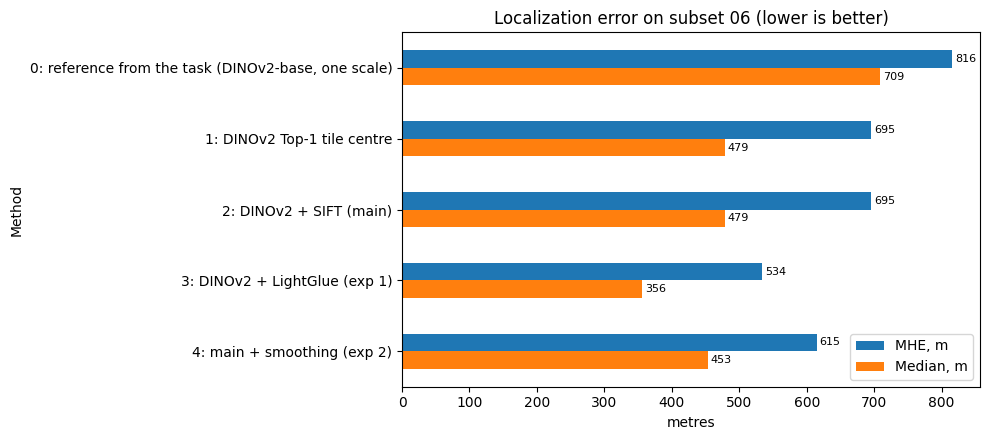

In [19]:
plot_df = metrics.set_index("Method")[["MHE, m", "Median, m"]]
ax = plot_df.plot.barh(figsize=(10, 4.5))
ax.invert_yaxis()  # reference on top, experiments below
ax.set(title="Localization error on subset 06 (lower is better)", xlabel="metres")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f", fontsize=8, padding=2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "errors_bars.png", dpi=120)
plt.show()

## 8: Visual check and best / worst examples (main pipeline)

Green = ground truth, red = prediction, white line = error. Points outside the map are not drawn. The note on each example says why the error happened.

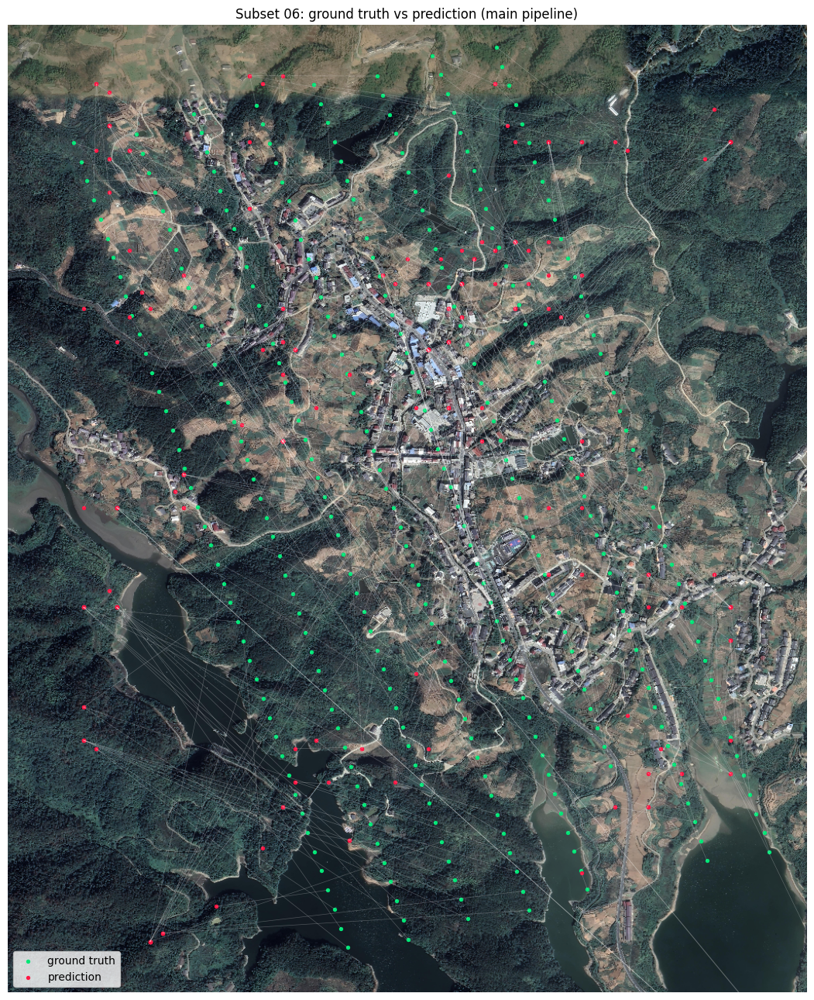

In [20]:
s = 8  # overview downscale
fig, ax = plt.subplots(figsize=(11, 13))
ax.imshow(satellite_rgb[::s, ::s])
for r in main.itertuples():
    ax.plot([r.gt_x / s, r.pred_x / s], [r.gt_y / s, r.pred_y / s], color="white", alpha=0.25, linewidth=0.5)
ax.scatter(main.gt_x / s, main.gt_y / s, s=8, c="#00e676", label="ground truth")
ax.scatter(main.pred_x / s, main.pred_y / s, s=8, c="#ff1744", label="prediction")
ax.set_xlim(0, MAP_W / s); ax.set_ylim(MAP_H / s, 0)
ax.set_title("Subset 06: ground truth vs prediction (main pipeline)")
ax.legend(loc="lower left"); ax.axis("off")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "map_gt_vs_pred.png", dpi=120); plt.show()

### LightGlue (experiment 1): map and matching examples
Red points were refined by SuperPoint + LightGlue; orange points fell back to the centre of the best tile. The matching examples below show one correct and one wrong match: with repeated buildings, LightGlue can match a similar place elsewhere.

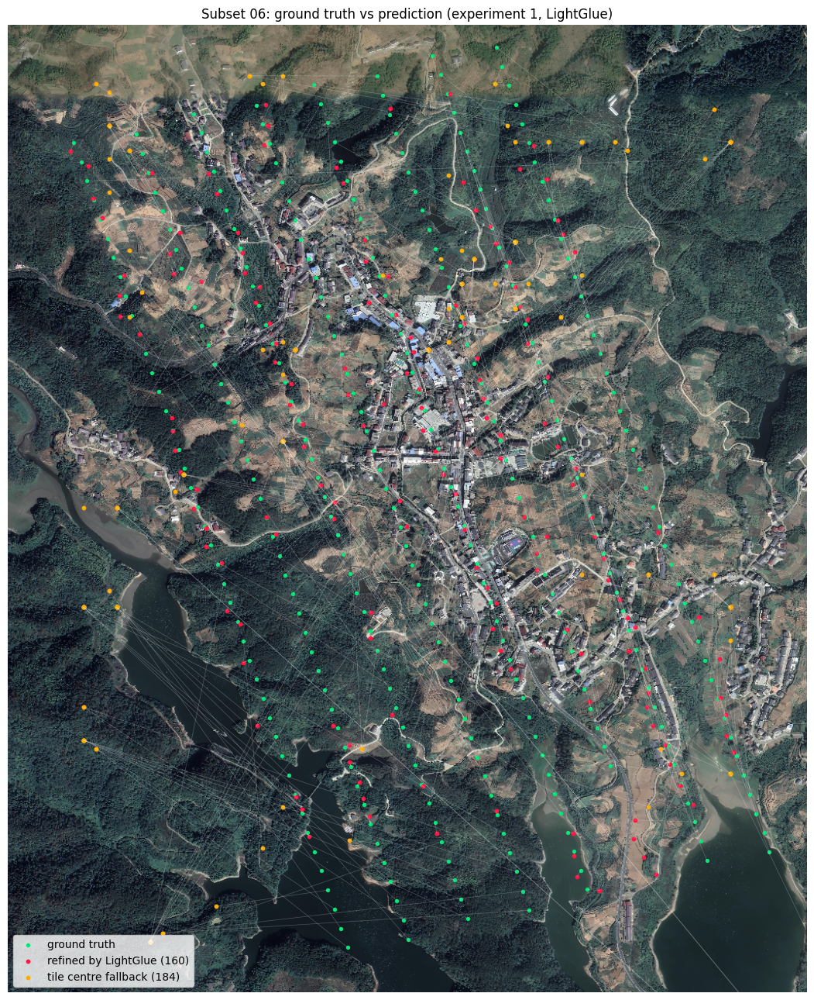

In [21]:
s = 8  # overview downscale
e = evals["3: DINOv2 + LightGlue (exp 1)"]
refined = e.source == "refined"

fig, ax = plt.subplots(figsize=(11, 13))
ax.imshow(satellite_rgb[::s, ::s])
for r in e.itertuples():
    ax.plot([r.gt_x / s, r.pred_x / s], [r.gt_y / s, r.pred_y / s], color="white", alpha=0.25, linewidth=0.5)
ax.scatter(e.gt_x / s, e.gt_y / s, s=8, c="#00e676", label="ground truth")
ax.scatter(e.pred_x[refined] / s, e.pred_y[refined] / s, s=10, c="#ff1744",
           label=f"refined by LightGlue ({int(refined.sum())})")
ax.scatter(e.pred_x[~refined] / s, e.pred_y[~refined] / s, s=10, c="#ffab00",
           label=f"tile centre fallback ({int((~refined).sum())})")
ax.set_xlim(0, MAP_W / s); ax.set_ylim(MAP_H / s, 0)
ax.set_title("Subset 06: ground truth vs prediction (experiment 1, LightGlue)")
ax.legend(loc="lower left"); ax.axis("off")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "map_lightglue.png", dpi=120); plt.show()

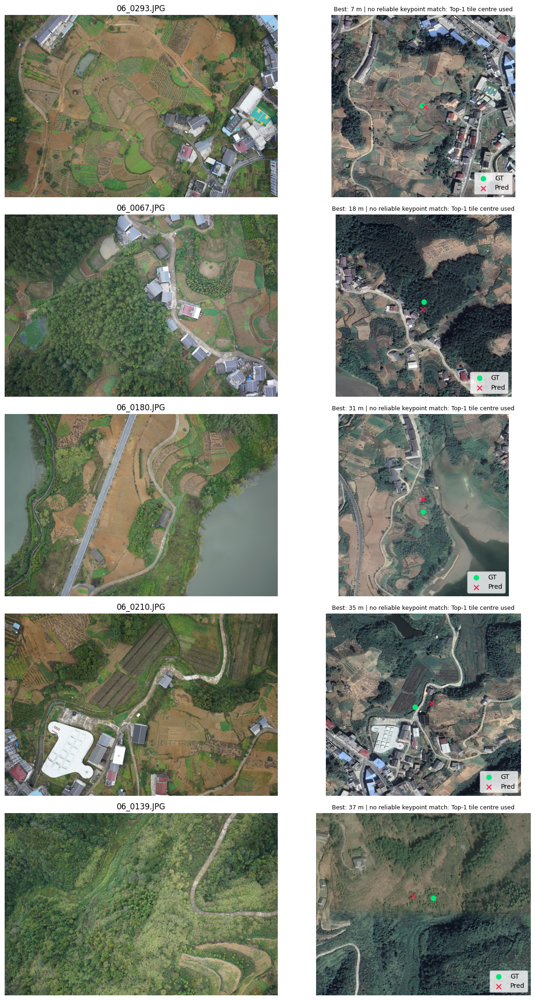

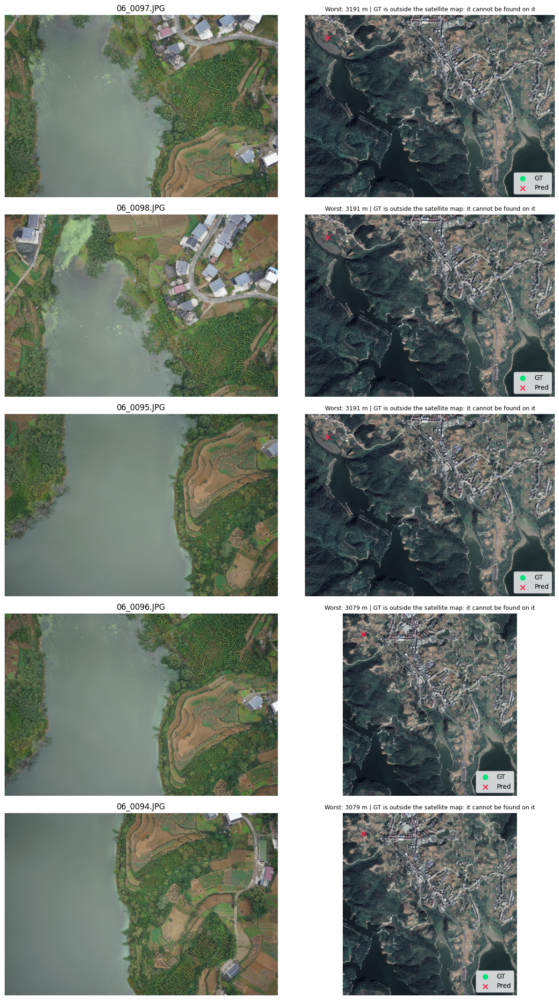

In [22]:
def error_note(r):
    if r.outside_map:
        return "GT is outside the satellite map: it cannot be found on it"
    if r.source == "refined":
        return f"refined by keypoint matching ({r.inliers} inliers)"
    return "no reliable keypoint match: Top-1 tile centre used"

def plot_examples(frame, title, path):
    fig, axes = plt.subplots(len(frame), 2, figsize=(13, 4.3 * len(frame)))
    for (a0, a1), r in zip(axes, frame.itertuples()):
        a0.imshow(read_rgb(DRONE_DIR / r.filename)); a0.set_title(r.filename); a0.axis("off")
        x0 = int(np.clip(min(r.gt_x, r.pred_x) - 700, 0, MAP_W - 1)); y0 = int(np.clip(min(r.gt_y, r.pred_y) - 700, 0, MAP_H - 1))
        x1 = int(np.clip(max(r.gt_x, r.pred_x) + 700, x0 + 1, MAP_W)); y1 = int(np.clip(max(r.gt_y, r.pred_y) + 700, y0 + 1, MAP_H))
        a1.imshow(satellite_rgb[y0:y1, x0:x1])
        a1.scatter(r.gt_x - x0, r.gt_y - y0, c="#00e676", s=55, label="GT")
        a1.scatter(r.pred_x - x0, r.pred_y - y0, c="#ff1744", marker="x", s=55, label="Pred")
        a1.set_xlim(0, x1 - x0); a1.set_ylim(y1 - y0, 0)
        a1.set_title(f"{title}: {r.error_m:.0f} m | {error_note(r)}", fontsize=9); a1.legend(loc="lower right"); a1.axis("off")
    plt.tight_layout(); plt.savefig(path, dpi=90); plt.show()

plot_examples(main.nsmallest(5, "error_m"), "Best", OUTPUT_DIR / "best5.png")
plot_examples(main.nlargest(5, "error_m"), "Worst", OUTPUT_DIR / "worst5.png")

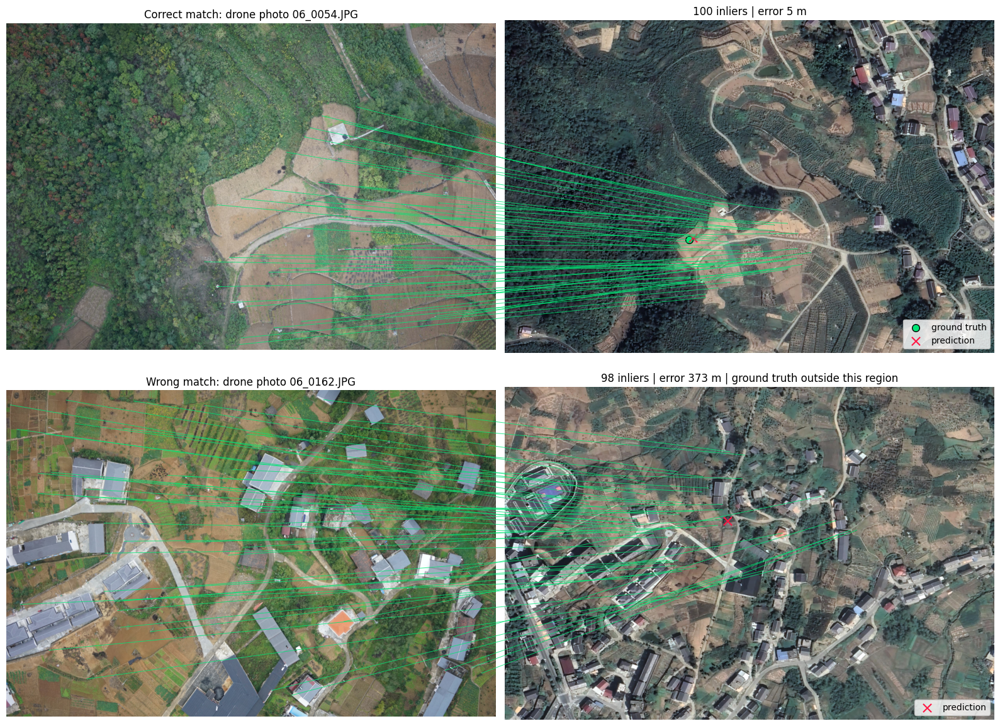

In [23]:
from matplotlib.patches import ConnectionPatch

# one correct and one wrong LightGlue match, each with a typical (median) number of inliers
e = evals["3: DINOv2 + LightGlue (exp 1)"]
ref = e[e.source == "refined"]
good = ref[ref.error_m <= 50].sort_values("inliers")
bad = ref[ref.error_m > 200].sort_values("inliers")
examples = [("Correct match", good.iloc[len(good) // 2]), ("Wrong match", bad.iloc[len(bad) // 2])]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
lines = []
for (a0, a1), (label, r) in zip(axes, examples):
    rec = tile_records[int(r.tile_idx)]
    q_img = resize_longest_side(read_rgb(DRONE_DIR / r.filename))
    if rec["rotation"] == 180:
        q_img = cv2.rotate(q_img, cv2.ROTATE_180)  # same orientation as used for matching
    roi_rgb, x0, y0 = crop_roi_at_center(rec["cx"], rec["cy"])
    src, dst = lg_match(lg_extract(q_img), lg_extract(roi_rgb))
    _, mask = robust_homography(src, dst)
    inl = np.where(mask.ravel().astype(bool))[0]
    gx, gy = r.gt_x - x0, r.gt_y - y0
    gt_inside = 0 <= gx < roi_rgb.shape[1] and 0 <= gy < roi_rgb.shape[0]
    a0.imshow(q_img); a0.set_title(f"{label}: drone photo {r.filename}"); a0.axis("off")
    a1.imshow(roi_rgb); a1.axis("off")
    if gt_inside:
        a1.scatter(gx, gy, c="#00e676", s=70, edgecolors="black", label="ground truth")
    a1.scatter(r.pred_x - x0, r.pred_y - y0, c="#ff1744", marker="x", s=90, label="prediction")
    a1.set_xlim(0, roi_rgb.shape[1]); a1.set_ylim(roi_rgb.shape[0], 0)
    a1.set_title(f"{len(inl)} inliers | error {r.error_m:.0f} m" + ("" if gt_inside else " | ground truth outside this region"))
    a1.legend(loc="lower right")
    rng = np.random.default_rng(SEED)
    lines += [(src[i], dst[i], a0, a1) for i in rng.choice(inl, size=min(50, len(inl)), replace=False)]
plt.tight_layout()
for p_q, p_m, a0, a1 in lines:
    fig.add_artist(ConnectionPatch(xyA=p_q, xyB=p_m, coordsA="data", coordsB="data",
                                   axesA=a0, axesB=a1, color="#00e676", linewidth=0.7, alpha=0.8))
plt.savefig(OUTPUT_DIR / "lightglue_match.png", dpi=110); plt.show()

## 9: Conclusions

**Result (MHE):** task reference 816 m · better tiles 695 m · + LightGlue (exp 1) **534 m** · + smoothing (exp 2) 615 m. With LightGlue, 32.8% of photos are within 50 m.

- Better tiles (three scales, 180° rotation, overlap) beat the task's reference.
- SIFT never passes the checks: drone and satellite images differ too much (season, light, forest and water).
- SuperPoint + LightGlue refines about half of the photos, precisely. The largest single improvement.
- Smoothing over neighbouring frames removes large jumps.
- Frames whose GPS lies outside the map cannot be localized.

**Limitations:** test-only data, so the experiments are not used to pick a winner and their combination was not evaluated. **Next step:** use the other subsets for validation and fine-tuning.

**References:** [UAV-VisLoc](https://github.com/IntelliSensing/UAV-VisLoc) · [DINOv2](https://github.com/facebookresearch/dinov2) · [LightGlue](https://github.com/cvg/LightGlue) · Lowe, *SIFT*, 2004.